In [1]:
TEKST_BREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)
TEKSTBREEDTE = TEKST_BREEDTE

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import bambi as bmb
import arviz as az
from pathlib import Path

FONT_TEKST = "Libertinus Serif"
FONT_CIJFERS = "Libertinus Math"

HOOFDKLEUR = "#007044"
PALET = ["#0067B9", "#FF9527", "#E100A3", "#9569BE", "#007044", "#00859B"]

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [FONT_TEKST],
    "font.size": CORPS,
    "figure.facecolor": "white",
    "savefig.bbox": "tight",
    "axes.unicode_minus": False,
})

DATA = Path("../../data/algemeen")
UITVOER = Path("../../fig/H8")

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [2]:
map_macro = Path("../../data/algemeen/gebeurtenisdata_macro")
excel_files = sorted([f for f in map_macro.glob("*.xlsx")])

print(len(excel_files))

dataframes = []
for file in excel_files:
    try:
        df = pd.read_excel(file)
        dataframes.append(df)
    except Exception as e:
        print(file.name)

df_macro = pd.concat(dataframes, ignore_index=True)


198
._MA#30830.xlsx


In [3]:
df_w3 = pd.read_excel("../../data/H8/geluidsoverlast_w3_nacht_allepersonen.xlsx")

In [4]:
df_meso = pd.read_excel("../../data/algemeen/gebeurtenisdata_meso/steekproefdatabank.xlsx")

In [5]:
print(df_macro.shape, df_w3.shape)
print([c for c in df_macro.columns if c in
       ["district", "year", "astro", "gender_inferred",
        "P_AGE_clean", "P_PROF_hisclass", "P_PROF_hisco",
        "archive_file", "Person ID", "Incident Number"]])

(383125, 42) (1823, 72)
['archive_file', 'year', 'district', 'Person ID', 'Incident Number', 'gender_inferred', 'P_PROF_hisco', 'P_PROF_hisclass', 'P_AGE_clean', 'astro']


In [6]:
HISCLASS5 = {1: "elite", 2: "elite", 3: "elite",
             4: "middenklasse", 5: "middenklasse",
             6: "arbeiders", 7: "arbeiders", 8: "arbeiders",
             9: "arbeiders", 10: "arbeiders", 11: "arbeiders", 12: "arbeiders"}

HORECA = [51020, 51050]   # herbergiers, hotelhouders / cabaretiers, koffiehuishouders

for df in (df_macro, df_w3):
    df["P_PROF_hisclass"] = pd.to_numeric(df["P_PROF_hisclass"], errors="coerce")
    df["P_PROF_hisco"] = pd.to_numeric(df["P_PROF_hisco"], errors="coerce")
    df["uitbater"] = df["P_PROF_hisco"].isin(HORECA)
    df.loc[df["uitbater"], "P_PROF_hisclass"] = 5
    df["klasse"] = df["P_PROF_hisclass"].map(HISCLASS5)

print(df_macro["P_PROF_hisclass"].value_counts().sort_index())
print(df_macro["klasse"].value_counts(dropna=False))
print(df_macro.loc[df_macro["uitbater"], "klasse"].value_counts())

P_PROF_hisclass
1.0       592
2.0      3836
3.0      4854
4.0      9161
5.0      5679
6.0       779
7.0     10662
8.0      1348
9.0     21602
10.0       56
11.0    13297
12.0      315
Name: count, dtype: int64
klasse
NaN             310944
arbeiders        48059
middenklasse     14840
elite             9282
Name: count, dtype: int64
klasse
middenklasse    2896
Name: count, dtype: int64


In [7]:
VROEG = (1877, 1891)
LAAT = (1919, 1939)
NACHTCATS = ["nacht", "avondschemering", "ochtendschemering"]

geluid = df_w3[["archive_file", "Person ID"]].drop_duplicates()
geluid["geluid"] = True

d = df_macro[df_macro["district"] == 3].merge(
    geluid, on=["archive_file", "Person ID"], how="left")
d["geluid"] = d["geluid"].fillna(False)

d = d[d["astro"].isin(NACHTCATS)].copy()
d["periode"] = np.where(d["year"].between(*VROEG), "vroeg",
                np.where(d["year"].between(*LAAT), "laat", None))

print(d.groupby("periode", dropna=False)
      .agg(personen=("geluid", "size"), geluid=("geluid", "sum")))

         personen  geluid
periode                  
laat        16750     597
vroeg       12867    1045
NaN          2301     174


/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_45272/1297078764.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d["geluid"] = d["geluid"].fillna(False)


In [8]:
# cijfers voor de tekst: waarom elite en middenklassevrouwen wegvallen
print("elite, geluid:", d[d["klasse"] == "elite"]["geluid"].sum())
print("middenklassevrouwen, geluid:",
      d[(d["klasse"] == "middenklasse")
        & (d["gender_inferred"] == "woman")]["geluid"].sum())
print("zonder beroep:", d["klasse"].isna().sum(), "van", len(d))

elite, geluid: 18
middenklassevrouwen, geluid: 15
zonder beroep: 24264 van 31918


In [9]:
print(d.groupby(["periode", "klasse", "uitbater"], observed=True)
      .agg(n=("geluid", "size"), geluid=("geluid", "sum")).to_string())

                                  n  geluid
periode klasse       uitbater              
laat    arbeiders    False     1879      76
        elite        False      499       9
        middenklasse False      722      31
                     True       160      17
vroeg   arbeiders    False     3093     241
        elite        False      193       8
        middenklasse False      381      32
                     True       126      22


In [10]:
print(d[d["klasse"] == "middenklasse"]
      .groupby(["periode", "gender_inferred", "uitbater"], observed=True)
      .agg(n=("geluid", "size"), geluid=("geluid", "sum")).to_string())

                                    n  geluid
periode gender_inferred uitbater             
laat    man             False     481      22
                        True       52       3
        uncertain       False       2       0
        unknown         False     193       9
                        True       54       9
        woman           False      46       0
                        True       54       5
vroeg   man             False     199      22
                        True       50      13
        uncertain       False       1       0
                        True        1       0
        unknown         False     140       6
                        True       53       6
        woman           False      41       4
                        True       22       3


In [11]:
m3 = d[d["periode"].notna()].copy()
m3["P_AGE_clean"] = pd.to_numeric(m3["P_AGE_clean"], errors="coerce")

m3 = m3[m3["gender_inferred"].isin(["man", "woman"])]
m3 = m3[m3["klasse"].notna()]
m3 = m3.dropna(subset=["P_AGE_clean"])

m3["geluid"] = m3["geluid"].astype(int)
m3["vrouw"] = (m3["gender_inferred"] == "woman").astype(int)
m3["laat"] = (m3["periode"] == "laat").astype(int)
m3["leeftijd10"] = (m3["P_AGE_clean"] - 30) / 10
m3["klasse"] = pd.Categorical(m3["klasse"],
                              categories=["arbeiders", "middenklasse", "elite"])

print(m3.groupby(["periode", "klasse"], observed=True)
      .agg(n=("geluid", "size"), geluid=("geluid", "sum")))

                         n  geluid
periode klasse                    
laat    arbeiders     1153      39
        middenklasse   469      21
        elite          188       6
vroeg   arbeiders     1882     157
        middenklasse   148      27
        elite           33       5


In [12]:
FORMULE3 = "geluid ~ (vrouw + klasse + leeftijd10) * laat"

model3 = bmb.Model(FORMULE3, m3, family="bernoulli")
idata3 = model3.fit(draws=2000, tune=2000, chains=4, cores=1,
                    random_seed=42, target_accept=0.95)

print("divergences:", idata3.sample_stats["diverging"].sum().item())
print(list(idata3.posterior.data_vars))
print(az.summary(idata3, kind="stats")[["mean", "sd", "hdi_3%", "hdi_97%"]])

Modeling the probability that geluid==1


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [Intercept, vrouw, klasse, leeftijd10, laat, vrouw:laat, klasse:laat, leeftijd10:laat]


Output()

Output()

Output()

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 88 seconds.


divergences: 0
['Intercept', 'vrouw', 'klasse', 'leeftijd10', 'laat', 'vrouw:laat', 'klasse:laat', 'leeftijd10:laat']
                            mean     sd  hdi_3%  hdi_97%
Intercept                 -2.283  0.087  -2.443   -2.120
vrouw                     -0.783  0.306  -1.344   -0.207
klasse[elite]              0.561  0.521  -0.484    1.461
klasse[middenklasse]       0.959  0.236   0.525    1.412
leeftijd10                -0.303  0.067  -0.432   -0.182
laat                      -0.999  0.197  -1.359   -0.624
vrouw:laat                 0.687  0.508  -0.301    1.596
klasse:laat[elite]        -0.664  0.698  -1.920    0.687
klasse:laat[middenklasse] -0.619  0.371  -1.298    0.076
leeftijd10:laat            0.121  0.129  -0.125    0.351


In [13]:
post3 = idata3.posterior

def trekken(naam, niveau=None):
    v = post3[naam]
    if niveau is not None:
        dim = [d for d in v.dims if d not in ("chain", "draw")][0]
        v = v.sel({dim: niveau})
    return v.values.flatten()

TERMEN3 = [
    ("vrouw t.o.v. man", "vrouw", None),
    ("middenklasse t.o.v. arbeiders", "klasse", "middenklasse"),
    ("elite t.o.v. arbeiders", "klasse", "elite"),
    ("per tien jaar ouder", "leeftijd10", None),
]

laat = trekken("laat")
lo_l, hi_l = np.percentile(np.exp(laat), [3, 97])
print(f"laat: odds-ratio {np.exp(laat).mean():.2f} [{lo_l:.2f}, {hi_l:.2f}]\n")

rijen3 = []
for label, naam, niveau in TERMEN3:
    basis = trekken(naam, niveau)
    inter = trekken(f"{naam}:laat", niveau)

    for periode, waarden in [("vroeg", basis), ("laat", basis + inter)]:
        lo, hi = np.percentile(waarden, [3, 97])
        rijen3.append({"term": label, "periode": periode,
                       "gem": waarden.mean(), "lo": lo, "hi": hi})

    lo, hi = np.percentile(inter, [3, 97])
    print(f"{label}: verandering {inter.mean():+.2f} [{lo:+.2f}, {hi:+.2f}]  "
          f"P(zwakker in interbellum)={np.mean(np.sign(basis) * inter < 0):.2f}")

res3 = pd.DataFrame(rijen3)
print("\n" + res3.round(2).to_string(index=False))

laat: odds-ratio 0.38 [0.25, 0.53]

vrouw t.o.v. man: verandering +0.69 [-0.28, +1.62]  P(zwakker in interbellum)=0.91
middenklasse t.o.v. arbeiders: verandering -0.62 [-1.31, +0.07]  P(zwakker in interbellum)=0.96
elite t.o.v. arbeiders: verandering -0.66 [-1.96, +0.66]  P(zwakker in interbellum)=0.88
per tien jaar ouder: verandering +0.12 [-0.12, +0.36]  P(zwakker in interbellum)=0.83

                         term periode   gem    lo    hi
             vrouw t.o.v. man   vroeg -0.78 -1.39 -0.23
             vrouw t.o.v. man    laat -0.10 -0.90  0.61
middenklasse t.o.v. arbeiders   vroeg  0.96  0.51  1.40
middenklasse t.o.v. arbeiders    laat  0.34 -0.20  0.87
       elite t.o.v. arbeiders   vroeg  0.56 -0.50  1.46
       elite t.o.v. arbeiders    laat -0.10 -1.01  0.71
          per tien jaar ouder   vroeg -0.30 -0.43 -0.18
          per tien jaar ouder    laat -0.18 -0.39  0.02


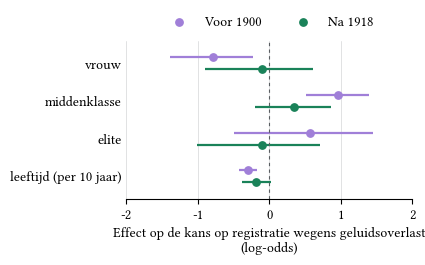

In [14]:
fig, ax = plt.subplots(figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.58))

KLEUR = {"vroeg": KLEUR_VROEG, "laat": KLEUR_LAAT}
LABEL = {"vroeg": "Voor 1900", "laat": "Na 1918"}
OFFSET = {"vroeg": -0.16, "laat": 0.16}

labels3 = ["vrouw", "middenklasse", "elite", "leeftijd (per 10 jaar)"]
termen3 = [t[0] for t in TERMEN3]

for periode in ("vroeg", "laat"):
    sub = res3[res3["periode"] == periode]
    y = [termen3.index(t) + OFFSET[periode] for t in sub["term"]]

    ax.hlines(y, sub["lo"], sub["hi"], color=KLEUR[periode], lw=1.6)
    ax.scatter(sub["gem"], y, color=KLEUR[periode], s=28, zorder=3,
               label=LABEL[periode])

ax.axvline(0, color="#5A5E62", lw=0.8, linestyle=(0, (3, 3)))
ax.set_xlim(-2, 2)

ax.set_yticks(range(len(labels3)))
ax.set_yticklabels(labels3)
ax.set_ylim(-0.6, len(labels3) - 0.4)
ax.invert_yaxis()

ax.set_xlabel("Effect op de kans op registratie wegens geluidsoverlast\n(log-odds)")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)



ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x")
ax.tick_params(axis="y", length=0)

plt.subplots_adjust(left=0.30, right=0.98, top=0.88, bottom=0.24)
pas_breedte_aan(fig)
fig.savefig(UITVOER / "8.10_sociale_verschillen.png", dpi=300)
plt.show()

In [15]:
m3 = d[d["periode"].notna()].copy()
m3["P_AGE_clean"] = pd.to_numeric(m3["P_AGE_clean"], errors="coerce")

m3 = m3[m3["gender_inferred"].isin(["man", "woman"])]
m3 = m3[m3["klasse"].notna()]
m3 = m3.dropna(subset=["P_AGE_clean"])

m3["geluid"] = m3["geluid"].astype(int)
m3["vrouw"] = (m3["gender_inferred"] == "woman").astype(int)
m3["laat"] = (m3["periode"] == "laat").astype(int)
m3["leeftijd10"] = (m3["P_AGE_clean"] - 30) / 10
m3["klasse"] = pd.Categorical(m3["klasse"],
                              categories=["arbeiders", "middenklasse", "elite"])

print(m3.groupby(["periode", "klasse"], observed=True)
      .agg(n=("geluid", "size"), geluid=("geluid", "sum")))
print("\ntotaal:", len(m3), "geluid:", m3["geluid"].sum())

                         n  geluid
periode klasse                    
laat    arbeiders     1153      39
        middenklasse   469      21
        elite          188       6
vroeg   arbeiders     1882     157
        middenklasse   148      27
        elite           33       5

totaal: 3873 geluid: 255


In [16]:
NACHTCATS = ["nacht", "avondschemering", "ochtendschemering"]
MISSING = ["unknown", "onbekend", "", "-", "?"]

d = df_meso.copy()
d["subcat"] = d["subcategory"].str.strip().str.lower()
d["subcat"] = d["subcat"].replace({"verbaal geweld": "verbaal geweld",
                                   "fysiek geweld": "fysiek geweld"})  # casing valt al weg
d = d.replace(MISSING, pd.NA)

d_nacht = d[d["E_TIME_astro"].isin(NACHTCATS)]
print(len(d), "->", len(d_nacht), "nachtelijke registraties")
print(d_nacht["subcat"].value_counts().head(15))

5840 -> 2131 nachtelijke registraties
subcat
dronkenschap        345
overig              198
wanorder            196
fysiek geweld       162
dienstmededeling    138
nachtlawaai         130
entertainment       112
diefstal             99
ongeluk              87
zeden                81
belemmering          67
verbaal geweld       64
wildplassen          59
bedelarij            52
vandalisme           49
Name: count, dtype: int64


In [17]:
SOC = {"gender": "gender", "leeftijd": "age", "beroep": "prof_hisco"}

def dekking(data, min_n=30):
    t = (data.assign(**{k: data[v].notna() for k, v in SOC.items()})
             .groupby("subcat")[list(SOC)].mean().mul(100).round(1))
    t["N"] = data["subcat"].value_counts()
    t["volledig"] = (data.groupby("subcat")[list(SOC.values())]
                         .apply(lambda g: g.notna().all(axis=1).mean() * 100).round(1))
    return t[t["N"] >= min_n].sort_values("N", ascending=False)

print(dekking(d_nacht))
print("\nNachtlawaai t.o.v. mediaan:")
t = dekking(d_nacht)
print((t.loc["nachtlawaai", list(SOC) + ["volledig"]] - t[list(SOC) + ["volledig"]].median()).round(1))

                  gender  leeftijd  beroep    N  volledig
subcat                                                   
dronkenschap       100.0      85.8    68.7  345      62.9
overig             100.0      50.5    51.0  198      28.8
wanorder            99.5      69.4    57.1  196      42.9
fysiek geweld      100.0      62.3    54.3  162      34.6
dienstmededeling   100.0      26.8    68.1  138      16.7
nachtlawaai        100.0      71.5    62.3  130      45.4
entertainment      100.0      88.4    92.0  112      81.2
diefstal           100.0      67.7    53.5   99      42.4
ongeluk             98.9      79.3    18.4   87      10.3
zeden              100.0      49.4    86.4   81      42.0
belemmering        100.0      76.1    79.1   67      65.7
verbaal geweld     100.0      78.1    46.9   64      37.5
wildplassen        100.0      86.4    50.8   59      47.5
bedelarij          100.0      96.2    21.2   52      19.2
vandalisme         100.0      61.2    57.1   49      38.8
colportage    

In [18]:
KEY = ["archive_file", "Person ID"]

print(df_w3["archive_file"].iloc[:3].tolist())
print(df_macro["archive_file"].iloc[:3].tolist())   # zelfde formaat?

df_macro["geluid"] = df_macro.set_index(KEY).index.isin(df_w3.set_index(KEY).index)
print(df_macro["geluid"].sum(), "van", len(df_w3), "in df_w3")

['731#1597', 'MA#17624', 'MA#17881']
['1253#4', '1253#4', '1253#4']


1817 van 1823 in df_w3


In [19]:
SOC = ["gender_inferred", "P_AGE_clean", "P_PROF_hisclass"]

macro = df_macro[(df_macro["district"] == 3) & df_macro["astro"].isin(NACHTCATS)].copy()
macro["periode"] = pd.Categorical(
    np.where(macro["year"].between(*VROEG), "vroeg",
             np.where(macro["year"].between(*LAAT), "laat", "tussen")),
    categories=["vroeg", "tussen", "laat"],
)
macro["P_AGE_clean"] = pd.to_numeric(macro["P_AGE_clean"], errors="coerce")
macro["klasse3"] = macro["klasse"].map({"arbeiders": "Arbeidersklasse",
                                        "middenklasse": "Middenklasse",
                                        "elite": "Elite"})

In [20]:
macro[SOC] = macro[SOC].replace(["unknown", "onbekend", "", "-", "?", "nan"], pd.NA)

g = macro[macro["geluid"]]
print(len(g), "geluid in nacht/w3")
print(g["periode"].value_counts())
print(g.dropna(subset=SOC)["periode"].value_counts())   # vergelijk met 177 / 56

1816 geluid in nacht/w3
periode
vroeg     1045
laat       597
tussen     174
Name: count, dtype: int64
periode
vroeg     189
laat       66
tussen     32
Name: count, dtype: int64


In [21]:
mp = macro[macro["periode"].isin(["vroeg", "laat"])].dropna(subset=SOC)
print(mp.groupby("periode").size(), mp["geluid"].sum(), len(mp))

periode
vroeg     2066
tussen       0
laat      1812
dtype: int64 255 3878


/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_45272/49070820.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(mp.groupby("periode").size(), mp["geluid"].sum(), len(mp))


In [22]:
BINS = [0, 5, 14, 24, 64, 120]          # jouw grenzen uit H1
LABELS = ["kind", "schoolgaand", "jongvolwassene", "volwassene", "ouderen"]
macro["leeftijdscat"] = pd.cut(macro["P_AGE_clean"], bins=BINS, labels=LABELS)

VARS = ["gender_inferred", "leeftijdscat", "P_PROF_hisclass"]

def compositie(data, var):
    t = (data.dropna(subset=[var])
             .groupby("geluid", observed=True)[var]
             .value_counts(normalize=True).unstack("geluid").mul(100))
    t.columns = ["Overige", "Nachtlawaai"]
    t["Ratio"] = t["Nachtlawaai"] / t["Overige"]
    t["N"] = data.loc[data["geluid"], var].value_counts()
    return t.round(2)

vl = macro[macro["periode"].isin(["vroeg", "laat"])]
for p in ["vroeg", "laat"]:
    print(f"\n=== {p} ===")
    for var in VARS:
        print(f"\n{var}")
        print(compositie(vl[vl["periode"] == p], var))


=== vroeg ===

gender_inferred
                 Overige  Nachtlawaai  Ratio      N
gender_inferred                                    
man                80.57        75.91   0.94  460.0
uncertain           0.12          NaN    NaN    NaN
woman              19.30        24.09   1.25  146.0

leeftijdscat
                Overige  Nachtlawaai  Ratio    N
leeftijdscat                                    
kind               1.50         1.00   0.67    4
schoolgaand        7.00         3.00   0.43   12
jongvolwassene    25.87        35.25   1.36  141
volwassene        63.13        60.00   0.95  240
ouderen            2.50         0.75   0.30    3

P_PROF_hisclass
                 Overige  Nachtlawaai  Ratio      N
P_PROF_hisclass                                    
1.0                 0.69          NaN    NaN    NaN
2.0                 3.38         1.32   0.39    4.0
3.0                 1.23         1.32   1.07    4.0
4.0                 6.91         5.28   0.76   16.0
5.0                 6.

                Overige  Nachtlawaai  Ratio    N
leeftijdscat                                    
kind               0.16         0.00   0.00    0
schoolgaand        1.55         0.00   0.00    0
jongvolwassene    17.32        17.48   1.01   36
volwassene        77.26        82.52   1.07  170
ouderen            3.70         0.00   0.00    0

P_PROF_hisclass
                 Overige  Nachtlawaai  Ratio     N
P_PROF_hisclass                                   
1.0                 1.31          NaN    NaN   NaN
2.0                 6.14          NaN    NaN   NaN
3.0                 8.22         6.77   0.82   9.0
4.0                16.76        13.53   0.81  18.0
5.0                 9.91        22.56   2.28  30.0
6.0                 0.80          NaN    NaN   NaN
7.0                13.78        12.78   0.93  17.0
8.0                 2.33          NaN    NaN   NaN
9.0                22.29        27.82   1.25  37.0
10.0                0.06          NaN    NaN   NaN
11.0               18.13    

In [23]:
plt.rcParams.update({"font.family": "Libertinus Serif", "font.size": CORPS})
NACHTBLAUW, STEENGRIJS = KLEUR_NACHT, "#96999B"
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
FIG = Path("../../fig/H8"); FIG.mkdir(exist_ok=True)

def bewaar(fig, naam):
    for ext in ("png",):
        pas_breedte_aan(fig, tight=True)
        fig.savefig(FIG / f"{naam}.{ext}", dpi=300, bbox_inches="tight")

KLASSE3 = {**{i: "Elite" for i in range(1, 4)},
           **{i: "Middenklasse" for i in (4, 5)},
           **{i: "Arbeidersklasse" for i in range(6, 13)}}
macro["klasse3"] = macro["P_PROF_hisclass"].astype("Int64").map(KLASSE3)

vl = macro[macro["periode"].isin(["vroeg", "laat"])]
PERIODES = {"vroeg": "1877–1891", "laat": "1919–1939"}

In [24]:
plt.rcParams.update({"font.family": "Libertinus Serif", "font.size": CORPS})
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
FIG = Path("../../fig/H8"); FIG.mkdir(exist_ok=True)

def bewaar(fig, naam):
    for ext in ("png",):
        pas_breedte_aan(fig, tight=True)
        fig.savefig(FIG / f"{naam}.{ext}", dpi=300, bbox_inches="tight")

PERIODES = {"vroeg": "1877–1891", "laat": "1919–1939"}
g = macro[macro["geluid"] & macro["periode"].isin(["vroeg", "laat"])]

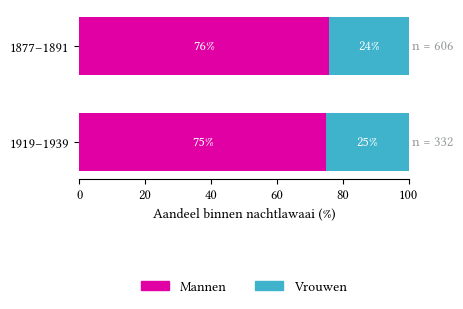

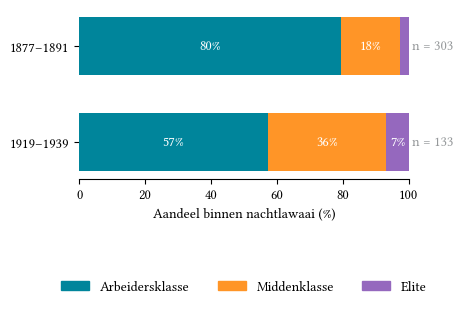

In [25]:
def gestapeld(var, volgorde, kleuren, labels, naam, xlabel):
    fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, 2.2))
    for i, (p, periodelabel) in enumerate(PERIODES.items()):
        d = g[g["periode"] == p].dropna(subset=[var])
        aandeel = d[var].value_counts(normalize=True).mul(100).reindex(volgorde).fillna(0)
        links = 0
        for cat, kleur in zip(volgorde, kleuren):
            ax.barh(i, aandeel[cat], left=links, color=kleur, height=0.6)
            if aandeel[cat] >= 6:
                ax.text(links + aandeel[cat] / 2, i, f"{aandeel[cat]:.0f}%",
                        ha="center", va="center", color="white", fontsize=CORPS)
            links += aandeel[cat]
        ax.text(101, i, f"n = {len(d)}", va="center", fontsize=CORPS, color="#96999B")

    ax.set_yticks(range(len(PERIODES)))
    ax.set_yticklabels(PERIODES.values())
    ax.set_xlim(0, 100); ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right", "left"]].set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=k) for k in kleuren]
    ax.legend(handles, labels, frameon=False, ncol=len(labels),
              loc="lower center", bbox_to_anchor=(0.5, -0.75))
    #bewaar(fig, naam)

gestapeld("gender_inferred", ["man", "woman"],
          [KLEUR_MAN, KLEUR_VROUW], ["Mannen", "Vrouwen"],
          "b_compositie_gender", "Aandeel binnen nachtlawaai (%)")

gestapeld("klasse3", ["Arbeidersklasse", "Middenklasse", "Elite"],
          ["#00859B", "#FF9527", "#9568be"],
          ["Arbeidersklasse", "Middenklasse", "Elite"],
          "4.7_compositie_klasse", "Aandeel binnen nachtlawaai (%)")

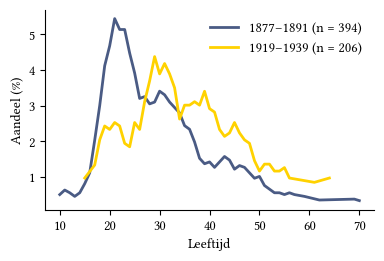

In [26]:
fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, 2.6))
for p, kleur in zip(PERIODES, ["#4a5b84", "#ffd200"]):
    d = g[(g["periode"] == p)]["P_AGE_clean"].dropna()
    d = d[d.between(10, 70)]
    verdeling = (d.round().astype(int).value_counts(normalize=True)
                  .sort_index().mul(100)
                  .rolling(5, center=True, min_periods=3).mean())
    ax.plot(verdeling.index, verdeling.values, color=kleur, lw=2,
            label=f"{PERIODES[p]} (n = {len(d)})")
ax.set_xlabel("Leeftijd"); ax.set_ylabel("Aandeel (%)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
#bewaar(fig, "b_compositie_leeftijd")

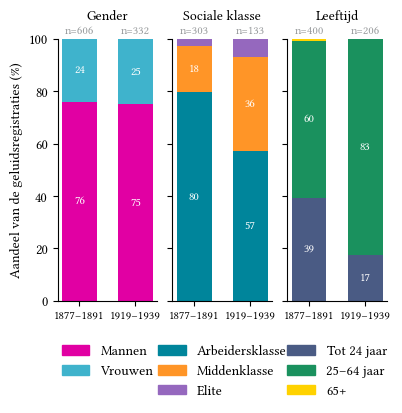

In [27]:
plt.rcParams.update({"font.family": "Libertinus Serif", "font.size": CORPS})
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)

PERIODES = {"vroeg": "1877–1891", "laat": "1919–1939"}
g = macro[macro["geluid"] & macro["periode"].isin(["vroeg", "laat"])].copy()

g["leeftijd3"] = pd.cut(g["P_AGE_clean"], [0, 24, 64, 120],
                        labels=["Tot 24 jaar", "25–64 jaar", "65+"])

PANELEN = [
    ("gender_inferred", ["man", "woman"], ["Mannen", "Vrouwen"],
     [KLEUR_MAN, KLEUR_VROUW], "Gender"),
    ("klasse3", ["Arbeidersklasse", "Middenklasse", "Elite"],
     ["Arbeidersklasse", "Middenklasse", "Elite"],
     ["#00859B", "#FF9527", "#9568be"], "Sociale klasse"),
    ("leeftijd3", ["Tot 24 jaar", "25–64 jaar", "65+"],
     ["Tot 24 jaar", "25–64 jaar", "65+"],
     ["#4a5b84", "#1A915E", "#ffd200"], "Leeftijd"),
]

fig, axen = plt.subplots(1, 3, figsize=(TEKSTBREEDTE, 3.4), sharey=True)

for ax, (var, volgorde, labels, kleuren, titel) in zip(axen, PANELEN):
    for i, p in enumerate(PERIODES):
        d = g[g["periode"] == p].dropna(subset=[var])
        aandeel = (d[var].value_counts(normalize=True).mul(100)
                    .reindex(volgorde).fillna(0))
        onder = 0
        for cat, kleur in zip(volgorde, kleuren):
            ax.bar(i, aandeel[cat], bottom=onder, color=kleur, width=0.62)
            if aandeel[cat] >= 8:
                ax.text(i, onder + aandeel[cat] / 2, f"{aandeel[cat]:.0f}",
                        ha="center", va="center", color="white", fontsize=CORPS_KLEIN)
            onder += aandeel[cat]
        ax.text(i, 102, f"n={len(d)}", ha="center", fontsize=CORPS_KLEIN, color="#96999B")

    ax.set_xticks(range(len(PERIODES)))
    ax.set_xticklabels(PERIODES.values(), fontsize=CORPS_KLEIN)
    ax.set_title(titel, fontsize=CORPS, pad=14)
    ax.set_ylim(0, 100)
    ax.spines[["top", "right"]].set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=k) for k in kleuren]
    ax.legend(handles, labels, frameon=False, fontsize=CORPS, ncol=1,
              loc="upper center", bbox_to_anchor=(0.5, -0.12))

axen[0].set_ylabel("Aandeel van de geluidsregistraties (%)", fontsize=CORPS)
fig.subplots_adjust(wspace=0.15)

#fig.savefig("../../fig/H8/4.8_compositie_geluidsregistraties.png", dpi=300, bbox_inches="tight")